# Teste de aumento artificial e limpeza de dados de treino

Preservamos duas referências: **564 atrasos encontrados / 4.358 falsos alertas / 140 perdidos** e **613 encontrados / 6.774 falsos alertas / 91 perdidos**. A segunda é a versão do modelo de 614 com filtro mais restritivo.

Queremos saber se aumentar, repetir ou retirar exemplos do treino melhora o equilíbrio entre encontrar atrasos reais e evitar alertas falsos. **Calibração e teste continuam reais e completos.** Não apagamos erros da avaliação para melhorar números.

O estudo é exploratório: esse período histórico já foi consultado em pesquisas anteriores. Não é prova de um limite máximo, nem confirmação independente para uma operação atual.

## 1. Ambiente e referências preservadas

Pandas/NumPy organizam os dados. Imbalanced-learn fornece RandomOverSampler, SMOTENC e TomekLinks. Scikit-learn fornece imputação e escala para vizinhança. Mantemos o CatBoost de 350 árvores e profundidade 6 dos dois revisores, para isolar o efeito da amostragem.

Na raiz do repositório:

```powershell
.\.venv\Scripts\python.exe -m pip install -e "ML/final_risk_training[research]"
.\.venv\Scripts\python.exe -m pip install -e "ML/context_review_comparison[research]"
.\.venv\Scripts\python.exe -m pip install -e "ML/sampling_comparison[research]"
```

Selecione o Python dessa venv como kernel. O ZIP inclui os pacotes anteriores em `runtime_final` e `runtime_context`, para instalar primeiro quando estiver fora do repositório.

In [1]:
import os
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:
    os.environ[key]='4'
from pathlib import Path
import json,hashlib,joblib
import pandas as pd
import numpy as np
from IPython.display import display,Image,Markdown
import sampling_risk
from sampling_risk.study import load_data,run_development
from sampling_risk.resampling import METHODS,resample
from sampling_risk.evaluate import evaluate_final,export_models
from sampling_risk.checks import verify
from sampling_risk.reporting import report,paired_uncertainty
ROOT=Path(sampling_risk.__file__).resolve().parents[1]
WORK=ROOT/'artifacts';WORK.mkdir(exist_ok=True)
RETRAIN=False  # True refaz os novos ajustes; as cópias preservadas não são substituídas.
references=[]
for base in ['base_564','base_613']:
    metadata=json.loads((ROOT/'preservados'/base/'metadata.json').read_text(encoding='utf-8'))
    references.append({'modelo':base,**metadata['metrics']})
display(pd.DataFrame(references)[['modelo','TP','FP','FN','precision','recall']])

,modelo,TP,FP,FN,precision,recall
0,base_564,564,4358,140,0.114588,0.801136
1,base_613,613,6774,91,0.082984,0.870739


## 2. O que muda e o que limita o ganho

Os detectores anteriores permanecem congelados. Ajustamos novamente somente os revisores contextuais que decidem quais alertas manter. Isso preserva os pesos antigos para comparação e evita inventar datas de entrega para reajustar o modelo de duração.

A primeira etapa limita os acertos: o detector da referência 564 sinaliza até 564 atrasos nesta coorte. O detector anterior ao filtro de 613 sinaliza até 614; um revisor novo pode recuperar o atraso que o filtro antigo descartou, mas não os atrasos descartados pelo detector.

Os dados continuam sendo a mesma Olist de 2016–2018. O histórico de vendedor/rota usa somente entregas concluídas antes de cada despacho. **Os vetores sintéticos não entram nesse histórico.**

In [2]:
bundle=joblib.load(WORK/'data.joblib') if (WORK/'data.joblib').exists() else load_data(ROOT)
# Revalidamos a origem dos CSVs antes de usar o cache de resultados.
from logipredict_final.data import load_orders
data_check,manifest=load_orders()
assert bundle['manifest']==manifest
assert data_check.order_id.tolist()==bundle['data'].order_id.tolist()
data,context=bundle['data'],bundle['context']
oof=joblib.load(ROOT/'training_inputs/oof.joblib')
display(pd.Series(manifest['quality']))
display(pd.DataFrame(METHODS))
print('Teste real: 19.258 pedidos; 704 atrasos. Nenhuma amostragem será aplicada nele.')

raw_orders                       99441.000000
eligible_orders                  96281.000000
late_orders                       6531.000000
late_rate                            0.067833
sellers                           3095.000000
orders_with_missing_measure        503.000000
multiple_seller_orders            1252.000000
geo_rows_filtered_after_dedup       25.000000
dtype: float64

,name,family
0,controle,controle
1,duplicar_atrasos_2x,duplicacao
2,smotenc_atrasos_2x,sinteticos
3,smotenc_pontuais_125,sinteticos
4,reduzir_pontuais_50,eliminacao
5,manter_pontuais_dificeis_50,eliminacao
6,tomek_pontuais,eliminacao
7,repetir_falsos_alertas_dificeis,duplicacao
8,smotenc_atrasos_tomek,combinacao


Teste real: 19.258 pedidos; 704 atrasos. Nenhuma amostragem será aplicada nele.


## 3. Nove estratégias

- **Controle:** mesmos exemplos e parâmetros do revisor anterior. Precisa reproduzir exatamente os modelos preservados na avaliação final.
- **Duplicar atrasos:** aumenta a frequência de exemplos reais de atraso, sem criar informação nova.
- **SMOTENC de atrasos:** cria vetores próximos de atrasos reais no espaço de atributos.
- **SMOTENC de pontuais:** aumenta exemplos hipotéticos de entregas pontuais, para investigar redução de falsos alertas.
- **Retirada aleatória:** mantém todos os atrasos e metade dos pontuais do treino.
- **Manter pontuais difíceis:** mantém os atrasos e a metade dos pontuais com maior score histórico do detector. São os exemplos que mais se parecem com atrasos para a primeira etapa.
- **Tomek de pontuais:** procura pares vizinhos de classes diferentes e remove somente os pontuais de fronteira. Isso pode ajudar ou prejudicar; remover pontuais também pode aumentar alarmes.
- **Repetir falsos alertas difíceis:** triplica a presença do quarto mais difícil dos pontuais, mantendo todos os outros exemplos.
- **SMOTENC + Tomek:** combina geração de atrasos e limpeza de pontuais.

Nenhum método elimina atrasos reais do ajuste. As estratégias de exclusão não tocam a calibração nem o teste.

## 4. Como foram gerados os exemplos artificiais

SMOTENC utiliza vizinhos e categorias existentes. Geramos dentro do mesmo par de UFs; grupos com menos de dois exemplos da classe desejada são ignorados. Medianas e StandardScaler são aprendidos somente nos números do treino para que quilogramas, quilômetros e taxas não tenham influência arbitrária na vizinhança.

Mantemos os exemplos reais originais com seus valores e ausências. Só os novos vetores recebem a transformação inversa. Recalculamos proporções físicas, rotas de prefixos, dias da semana derivados e folgas de prazo; arredondamos contagens, limitamos taxas a [0,1] e preservamos vendedores ≤ itens e P50 ≤ P90.

**Ainda assim, são vetores hipotéticos de treinamento.** Não há uma entrega observada que comprove seu rótulo. Nem todas as relações entre atributos podem ser garantidas, inclusive a relação entre o score antigo interpolado e um pedido físico. O teste real é necessário para descobrir se essas aproximações ajudam ou apenas introduzem ruído.

Não usamos texto gerado por IA, datas de entrega inventadas ou pedidos artificiais importados na aplicação.

In [3]:
# Exemplo de auditoria com um pequeno treino histórico real, sem usar o teste final.
from context_risk.study import pool_for
x,y=pool_for(data,context,oof['records'],'modelo_564','2017-12-01','filter',True)
demo=[]
for method in METHODS:
    _,_,audit=resample(x,y,method)
    demo.append({k:v for k,v in audit.items() if k!='route_groups'})
display(pd.DataFrame(demo)[['method','input_rows','output_rows','synthetic_rows','duplicated_rows','removed_rows']])

,method,input_rows,output_rows,synthetic_rows,duplicated_rows,removed_rows
0,controle,71,71,0,0,0
1,duplicar_atrasos_2x,71,90,0,19,0
2,smotenc_atrasos_2x,71,84,13,0,0
3,smotenc_pontuais_125,71,81,10,0,0
4,reduzir_pontuais_50,71,45,0,0,26
5,manter_pontuais_dificeis_50,71,45,0,0,26
6,tomek_pontuais,71,68,0,0,3
7,repetir_falsos_alertas_dificeis,71,97,0,26,0
8,smotenc_atrasos_tomek,71,81,13,0,3


## 5. Validação temporal e escolha

São quatro meses futuros de validação por referência: dezembro/2017 e fevereiro, março e abril/2018. O revisor aprende com previsões históricas fora do ajuste do detector, com despacho anterior ao bloco de calibração e rótulo disponível antes do ajuste.

Cada transformação é ajustada novamente somente no treino daquela janela. Os vizinhos do SMOTENC/Tomek não podem enxergar calibração ou teste. A seleção usa 72 avaliações: 9 estratégias × 4 meses × 2 referências.

O corte procura preservar 99% dos atrasos identificados pelo detector na calibração da referência 564 e 95% na referência 613, como nas versões preservadas. O bloco de calibração é real. Mudanças de frequência de classes no treino não justificam usar o mesmo corte numérico automaticamente.

A nota mensal é `FP_ratio + 20 × max(0, 0,99 − retenção_de_TP)`, relativa ao controle sem amostragem. Acrescentamos 0,25 vezes o desvio entre meses. Quanto menor, melhor. A escolha é congelada antes dos novos resultados finais; comparamos também o melhor de cada família. A semente é 42. As referências podem ser executadas em paralelo, com quatro threads por ajuste.

In [4]:
files=['resampling.py','study.py','evaluate.py']
signature=hashlib.sha256(b''.join((ROOT/'sampling_risk'/f).read_bytes() for f in files)).hexdigest()
if RETRAIN:
    bundle=load_data(ROOT);joblib.dump(bundle,WORK/'data.joblib',compress=3)
    run_development(bundle,oof,WORK)
else:
    saved=json.loads((WORK/'signature.json').read_text(encoding='utf-8'))
    assert saved['source_sha256']==signature,'Código mudou: refaça explicitamente os novos treinos.'
selection=joblib.load(WORK/'selection.joblib')
display(selection['summary'].reset_index())
display(selection['frozen'])

,base,method,family,objective,std,retained_TP,worst_retention,FP_ratio,selection_score
0,base_564,controle,controle,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000
1,base_613,controle,controle,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000
2,base_564,tomek_pontuais,eliminacao,1.006820,0.024101,1.001137,0.996540,1.006820,1.012845
3,base_564,repetir_falsos_alertas_dificeis,duplicacao,1.012848,0.047152,1.004393,0.992537,1.012848,1.024636
4,base_613,smotenc_pontuais_125,sinteticos,1.063766,0.017916,1.011283,0.985169,1.039613,1.068245
5,base_564,smotenc_atrasos_tomek,combinacao,1.047300,0.111968,0.995606,0.979239,0.993493,1.075292
6,base_613,reduzir_pontuais_50,eliminacao,1.140309,0.251950,0.996373,0.959746,0.989038,1.203296
7,base_613,tomek_pontuais,eliminacao,1.176995,0.146201,0.988639,0.971259,0.988861,1.213545
8,base_564,smotenc_atrasos_2x,sinteticos,1.203641,0.378667,0.996623,0.948097,0.994126,1.298308
9,base_564,duplicar_atrasos_2x,duplicacao,1.381882,0.483191,0.977688,0.936000,0.936968,1.502680


{'selected': {'base_564': ['controle',
   'smotenc_atrasos_2x',
   'tomek_pontuais',
   'repetir_falsos_alertas_dificeis',
   'smotenc_atrasos_tomek'],
  'base_613': ['controle',
   'smotenc_pontuais_125',
   'reduzir_pontuais_50',
   'repetir_falsos_alertas_dificeis',
   'smotenc_atrasos_tomek']},
 'global_best': {'base_564': 'controle', 'base_613': 'controle'},
 'criterion': 'mean(FP_ratio + 20*max(0,0.99-TP_retention)) + 0.25*std; comparison to unresampled control',
 'primary_retention': {'base_564': 0.99, 'base_613': 0.95},
 'status': 'Frozen before new holdout metrics; exploratory reused historical cohort.'}

## 6. Resultado em pedidos reais

TP é atraso sinalizado corretamente; FP é pedido pontual que recebeu alarme; FN é atraso perdido. Precisão mede quantos alarmes estavam certos; recall mede a fração dos atrasos encontrados.

Os totais incluem prazos já vencidos no despacho. A tabela separa os acertos antecipados desses casos. A RF original sinaliza 130 casos já vencidos; o detector da família 613 sinaliza 132. Não atribuímos essa regra ao aprendizado novo.

,base,method,TP,FP,FN,precision,recall,accuracy,anticipated_TP,known_overdue_TP
0,base_564,preservado,564,4358,140,0.114588,0.801136,0.766435,434,130
1,base_564,controle,564,4358,140,0.114588,0.801136,0.766435,434,130
2,base_564,smotenc_atrasos_2x,564,4364,140,0.114448,0.801136,0.766123,434,130
3,base_564,tomek_pontuais,563,4335,141,0.114945,0.799716,0.767577,433,130
4,base_564,repetir_falsos_alertas_dificeis,563,4345,141,0.114711,0.799716,0.767058,433,130
5,base_564,smotenc_atrasos_tomek,564,4361,140,0.114518,0.801136,0.766279,434,130
6,base_613,preservado,613,6774,91,0.082984,0.870739,0.643525,481,132
7,base_613,controle,613,6774,91,0.082984,0.870739,0.643525,481,132
8,base_613,smotenc_pontuais_125,613,6733,91,0.083447,0.870739,0.645654,481,132
9,base_613,reduzir_pontuais_50,609,6646,95,0.083942,0.865057,0.649964,477,132


,base,method,removed_FP,lost_TP,recovered_TP,added_FP
0,base_564,preservado,NaN,NaN,NaN,NaN
1,base_564,controle,0.0,0.0,0.0,0.0
2,base_564,smotenc_atrasos_2x,0.0,0.0,0.0,6.0
3,base_564,tomek_pontuais,24.0,1.0,0.0,1.0
4,base_564,repetir_falsos_alertas_dificeis,16.0,1.0,0.0,3.0
5,base_564,smotenc_atrasos_tomek,2.0,0.0,0.0,5.0
6,base_613,preservado,NaN,NaN,NaN,NaN
7,base_613,controle,0.0,0.0,0.0,0.0
8,base_613,smotenc_pontuais_125,98.0,1.0,1.0,57.0
9,base_613,reduzir_pontuais_50,152.0,4.0,0.0,24.0


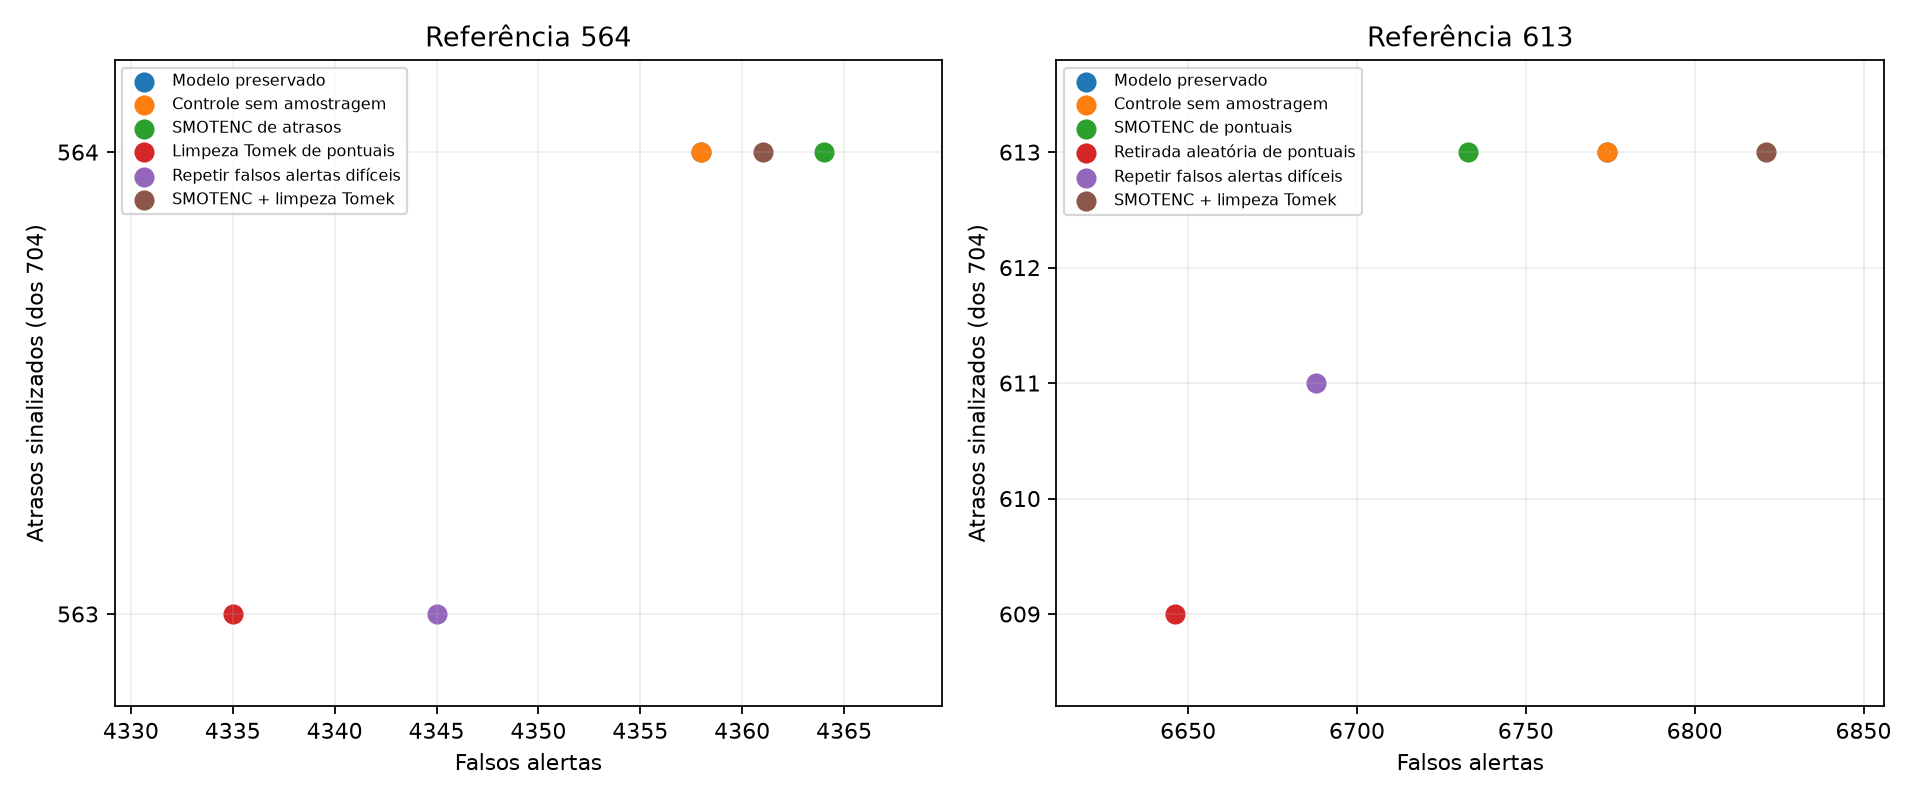

In [5]:
result=evaluate_final(bundle,oof,WORK) if RETRAIN else joblib.load(WORK/'evaluation.joblib')
display(result['table'][['base','method','TP','FP','FN','precision','recall','accuracy','anticipated_TP','known_overdue_TP']])
display(result['table'][['base','method','removed_FP','lost_TP','recovered_TP','added_FP']])
report(WORK)
display(Image(filename=str(WORK/'sampling_comparison.png')))

## 7. Acurácia e incerteza

Neste teste, 18.554 pedidos são pontuais. Um sistema que responda sempre “não atrasa” alcança **96,34% de acurácia e encontra zero atrasos**. Por isso, maior acurácia sozinha não demonstra melhor avaliação de risco.

Abaixo reamostramos semanas para estimar a variação das diferenças de TP e FP em relação às referências, sem treinar novamente. Isso não corrige o reaproveitamento histórico do período, nem substitui confirmação em uma amostra nova. Só usamos uma semente de treinamento nesta rodada.

In [6]:
display(paired_uncertainty(WORK))
audits=[]
for label,audit in result['audits'].items():
    audits.append({'model':label,**{k:v for k,v in audit.items() if k!='route_groups'}})
display(pd.DataFrame(audits)[['model','input_rows','output_rows','synthetic_rows','duplicated_rows','removed_rows']])

,model,delta_TP,delta_FP,delta_TP_low,delta_TP_high,delta_FP_low,delta_FP_high
0,base_564_controle,0,0,0.000,0.0,0.000,0.000
1,base_564_smotenc_atrasos_2x,0,6,0.000,0.0,1.000,13.000
2,base_564_tomek_pontuais,-1,-23,-3.000,0.0,-41.000,-7.000
3,base_564_repetir_falsos_alertas_dificeis,-1,-13,-3.000,0.0,-21.025,-5.000
4,base_564_smotenc_atrasos_tomek,0,3,0.000,0.0,-2.000,10.000
5,base_613_controle,0,0,0.000,0.0,0.000,0.000
6,base_613_smotenc_pontuais_125,0,-41,-3.000,3.0,-77.025,-6.000
7,base_613_reduzir_pontuais_50,-4,-128,-9.000,0.0,-212.050,-55.975
8,base_613_repetir_falsos_alertas_dificeis,-2,-86,-5.000,0.0,-144.000,-36.000
9,base_613_smotenc_atrasos_tomek,0,47,-2.025,3.0,-4.025,105.000


,model,input_rows,output_rows,synthetic_rows,duplicated_rows,removed_rows
0,base_564_controle,5284,5284,0,0,0
1,base_564_smotenc_atrasos_2x,5284,6656,1372,0,0
2,base_564_tomek_pontuais,5284,4987,0,0,297
3,base_564_repetir_falsos_alertas_dificeis,5284,7216,0,1932,0
4,base_564_smotenc_atrasos_tomek,5284,6499,1372,0,157
5,base_613_controle,17123,17123,0,0,0
6,base_613_smotenc_pontuais_125,17123,20538,3415,0,0
7,base_613_reduzir_pontuais_50,17123,10140,0,0,6983
8,base_613_repetir_falsos_alertas_dificeis,17123,24107,0,6984,0
9,base_613_smotenc_atrasos_tomek,17123,19712,3093,0,504


## 8. Exportação e verificações

Os dois originais continuam em `preservados`, com pesos e cortes idênticos. Os candidatos ficam em `modelos_novos`. Cada metadado registra quantos exemplos foram reais, sintéticos, repetidos ou removidos, além de versões e métricas.

Testamos determinismo, preservação dos exemplos originais, limites dos vetores gerados, exclusão do teste das fontes de amostragem, equivalência do controle, histórico sem eventos artificiais, serialização e sinalização HTTP de treinamento aumentado.

A geração artificial não roda na previsão. Os modelos continuam exigindo a integração contextual de vendedor e CEP; sem essas informações, o serviço usa somente a etapa original e avisa. Nenhuma versão é ativada no Node/Flutter por este notebook.

In [7]:
print('Exportados em:',export_models(WORK))
checks=verify(WORK)
display(pd.Series(checks))
print('Relatório:',report(WORK))
(WORK/'signature.json').write_text(json.dumps({'files':files,'source_sha256':signature},indent=2),encoding='utf-8')

Exportados em: D:\Documentos\FACULDADE\5 semestre\LogiPredictAI\ML\sampling_comparison\modelos_novos


real_holdout_19258_orders_704_delays                    True
two_preserved_model_hashes                              True
previous_models_and_notebooks_unchanged                 True
sampling_reproducible_and_input_unchanged               True
deletion_preserves_all_real_training_delays             True
synthetic_bounds_and_deterministic_relations            True
resampling_sources_exclude_calibration_and_holdout      True
no_synthetic_events_added_to_history                    True
serialization_and_pipeline_scores_match                 True
first_detector_gates_preserved                          True
synthetic_training_flag_matches_audit                   True
http_flags_fallback_and_validation                    passed
dtype: object

Relatório: D:\Documentos\FACULDADE\5 semestre\LogiPredictAI\ML\sampling_comparison\RESULTADOS.md


162

O serviço de homologação deste pacote informa quando o revisor usou SMOTENC no treino:

```powershell
$env:MODEL_DIR=(Resolve-Path "ML/sampling_comparison/modelos_novos/NOME_DO_MODELO").Path
python -m uvicorn sampling_risk.service:app --host 127.0.0.1 --port 8003
```

O JSON `exemplo_real.json` é um pedido real; os vetores sintéticos de treino não devem ser enviados como se fossem pedidos reais. Os pesos continuam experimentais e não foram ativados na aplicação.

Fontes técnicas: [aumento de amostras e SMOTENC](https://imbalanced-learn.org/stable/over_sampling.html), [redução e limpeza Tomek](https://imbalanced-learn.org/stable/under_sampling.html), [risco de vazamento ao reamostrar antes de separar os dados](https://imbalanced-learn.org/stable/common_pitfalls.html).